## Graph 2: Homework Strategies Under Different Deadline Pressures

**Graph Type:** Stacked Bar Chart

**Description:** This stacked bar chart will show the percentage of students who prefer different homework-solving strategies depending on the time remaining before a deadline. Each bar represents a different amount of time remaining, while the segments represent strategies such as solving problems independently, asking AI for hints or explanations, or asking AI for complete solutions. The graph will compare how students' preferred strategies differ across deadline conditions.

**Hypothesis:** As deadline pressure increases, students are more likely to rely on AI for homework assistance, including asking for hints, explanations, or complete solutions, rather than solving problems independently.

**Takeaway:** As deadline pressure increases, the percentage of students who prefer asking AI for hints or complete solutions increases from 27.1% to 83.1%. At the same time, the percentage of students who prefer solving problems independently decreases from 50.8% to 1.7%. This suggests that deadline pressure is associated with greater reliance on AI for homework assistance.

**Status:** Graph completed.

<Figure size 1200x700 with 0 Axes>

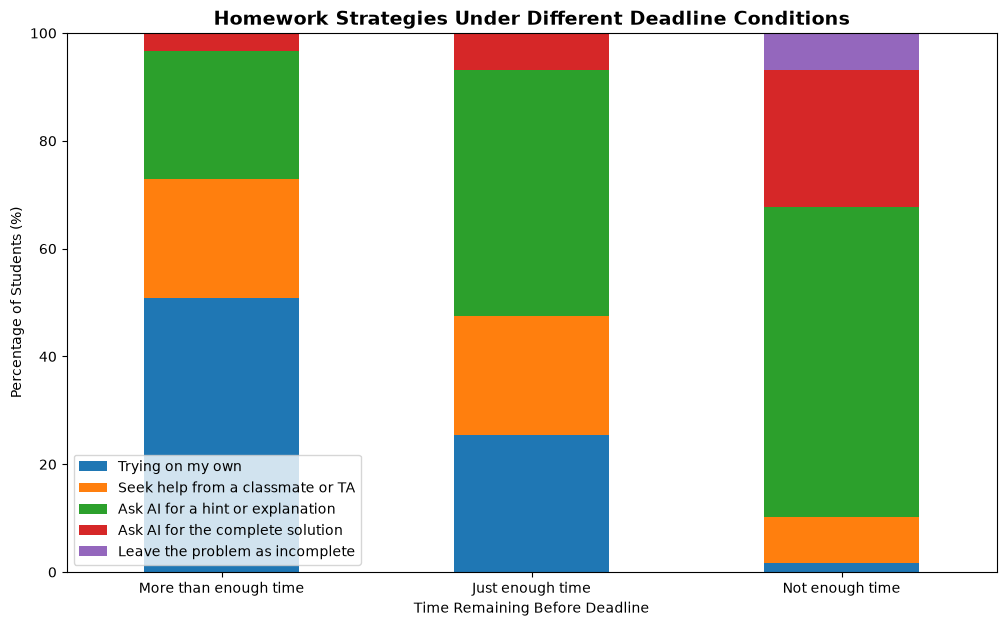

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

survey_df = pd.read_csv("survey.csv")

# Clean up the data by selecting the three homework strategy questions
homework_df = survey_df.loc[:, "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you have more than enough time to finish your assignment before the deadline]" : "If you have been working on a homework problem for 15 minutes without making any progress, what action are you most likely to take in each of the following scenarios? [When you don’t have enough time to finish your assignment before the deadline]"]

# Count the responses for each deadline situation
more_time = homework_df.iloc[:, 0].value_counts()
just_enough = homework_df.iloc[:, 1].value_counts()
not_enough = homework_df.iloc[:, 2].value_counts()

# Combine the counts into one DataFrame
cross_homework = pd.DataFrame({
    "More than enough time": more_time,
    "Just enough time": just_enough,
    "Not enough time": not_enough
}).T

# Replace missing response with 0
cross_homework = cross_homework.fillna(0)

# Set the order of homework strategies
strategy_order = [
    "Trying on my own",
    "Seek help from a classmate or TA",
    "Ask AI for a hint or explanation",
    "Ask AI for the complete solution",
    "Leave the problem as incomplete"
]

# Reorder the columns
cross_homework = cross_homework.reindex(columns=strategy_order, fill_value=0)


# Calculate the percentage of each homework strategy for each deadline situation
# Divide each count by the total responses in its row
percentage_homework = cross_homework.div(cross_homework.sum(axis=1), axis=0) * 100


# Create a 100% stacked bar chart to compare homework strategies under different deadline conditions
# Set figure size for better readability
plt.figure(figsize=(12, 7))

# Create the stacked bar chart
# stacked=True: Stacks different homework strategies into one bar
# Each bar represents 100% of responses for one deadline situation
percentage_homework.plot.bar(stacked=True, figsize=(12, 7))

# Add title and axis labels
plt.title('Homework Strategies Under Different Deadline Conditions', fontsize=14, fontweight='bold')
plt.xlabel('Time Remaining Before Deadline')
plt.ylabel('Percentage of Students (%)')

# Set the y-axis range from 0% to 100%
plt.ylim(0, 100)

# Rotate x-axis labels for readability
plt.xticks(rotation=0)

# Display the chart
plt.show()